# 03 — Model 2: operational response (multiclass classification)

`RandomForestClassifier` inside a scikit-learn `Pipeline`, so the one-hot encoding of `disruption_type`
is saved together with the model and the live pipeline can pass raw values.

In [1]:
from pathlib import Path

# Works both when Jupyter is started in the repo root and inside notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"
ART = ROOT / "artifacts"
DATA.mkdir(exist_ok=True)
ART.mkdir(exist_ok=True)

import json
import joblib
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

spec = json.loads((ART / "feature_spec.json").read_text())
CAT, NUM, ACTIONS = spec["model2_categorical"], spec["model2_numeric"], spec["actions"]

df = pd.read_csv(DATA / "model2_training.csv")
X_train, X_test, y_train, y_test = train_test_split(
    df[CAT + NUM], df["action"], test_size=0.2, stratify=df["action"], random_state=spec["seed"])

In [2]:
model2 = Pipeline([
    ("prep", ColumnTransformer([
        ("cat", OneHotEncoder(categories=[spec["disruption_types"]], handle_unknown="ignore"), CAT),
        ("num", "passthrough", NUM),
    ])),
    ("rf", RandomForestClassifier(
        n_estimators=150, max_depth=14, min_samples_leaf=3, class_weight="balanced", n_jobs=-1,
        random_state=spec["seed"])),
])
model2.fit(X_train, y_train)
pred = model2.predict(X_test)
print(classification_report(y_test, pred, digits=3))

                      precision    recall  f1-score   support

 CONTINUE_MONITORING      0.984     0.978     0.981      1201
DIVERT_TO_BACKUP_HUB      0.953     0.952     0.953       602
       HOLD_POSITION      0.960     0.952     0.956      1117
             REROUTE      0.933     0.949     0.941      1080

            accuracy                          0.959      4000
           macro avg      0.958     0.958     0.958      4000
        weighted avg      0.959     0.959     0.959      4000



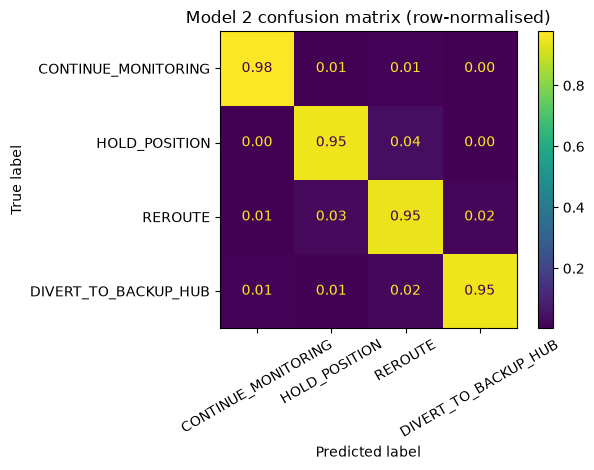

In [3]:
ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=ACTIONS, xticks_rotation=30, normalize="true",
                                        values_format=".2f")
plt.title("Model 2 confusion matrix (row-normalised)")
plt.tight_layout()

## Sanity check: the example from the project summary

Risk 0.87, alternative route with risk 0.18, +22 min detour, sufficient fuel, critical cargo → expect **REROUTE**.

In [4]:
example = pd.DataFrame([{
    "disruption_type": "FLOOD", "disruption_severity": 0.85, "current_route_risk": 0.87,
    "alternative_route_available": 1, "alternative_route_risk": 0.18, "extra_detour_minutes": 22,
    "fuel_level_pct": 65, "cargo_priority": 5, "estimated_hazard_duration_min": 240, "backup_hub_available": 1,
}])
print("Recommended:", model2.predict(example)[0])
pd.Series(model2.predict_proba(example)[0], index=model2.classes_).round(3)

Recommended: REROUTE


CONTINUE_MONITORING     0.021
DIVERT_TO_BACKUP_HUB    0.053
HOLD_POSITION           0.008
REROUTE                 0.918
dtype: float64

In [5]:
model2.set_params(rf__n_jobs=1)   # single-row live inference
joblib.dump(model2, ART / "model2_rf.joblib", compress=3)
print("Saved", ART / "model2_rf.joblib")

Saved /home/george/ReliefZ/artifacts/model2_rf.joblib
